# Construction Cost Prediction

## 1. Business question / Бизнес-задача
Educational construction analytics demonstration. All data are synthetic; AI assisted implementation.
Учебный проект на синтетических данных с помощью AI. Результаты не подтверждают эффективность на реальном оборудовании или стройке.

This notebook shows the complete workflow directly, including the generator, Pandas exploration, preprocessing, training, baseline comparison and evaluation. No import from `project.py` is needed.


## 2. Imports / Библиотеки
Pandas handles tabular data; NumPy generates examples; scikit-learn trains and evaluates models.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (mean_absolute_error, r2_score, average_precision_score,
    roc_auc_score, brier_score_loss, precision_score, recall_score,
    ConfusionMatrixDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance

## 3. Reproducible synthetic data / Синтетические данные
The outcome mechanism below is an educational assumption, not an engineering law. Missing predictors are added deliberately.

In [2]:
CONFIG = {'slug': '01_construction_cost_prediction', 'title': 'Construction Cost Prediction', 'kind': 'regression', 'target': 'final_cost_usd', 'unit': 'USD', 'group': 'project_id', 'seed': 41, 'question': 'At tender review, which work packages may exceed their initial budget?', 'decision': 'Prioritise estimator review and contingency discussion. Predictions are advisory; they do not authorise budgets.', 'availability': 'All predictors describe information available at tender review. Final cost is an outcome, never an input.', 'features': {'planned_cost_usd': 'Initial package budget, USD', 'quantity_m3': 'Planned work volume, cubic metres', 'complexity': 'Engineering complexity score, 1-5', 'market_index': 'Assumed material price index at estimation', 'remote_site': 'Remote site indicator, 0/1'}, 'limitation': 'Final costs follow a deliberately simplified synthetic formula. The model does not estimate commercial savings or replace quantity surveying.'}
FEATURES = list(CONFIG["features"])
TARGET = CONFIG["target"]
GROUP = CONFIG["group"]

def generate_data(seed=CONFIG['seed']):
    """Expose the assumptions instead of presenting synthetic relationships as facts."""
    rng = np.random.default_rng(seed)
    n = 1920
    sigmoid = lambda x: 1 / (1 + np.exp(-x))
    slug = CONFIG['slug']
    groups = np.repeat(np.arange(240), 8)
    volume = rng.uniform(100, 6000, n)
    budget = volume * rng.uniform(60, 130, n)
    complexity = rng.integers(1, 6, n)
    market = rng.uniform(0.9, 1.25, n)
    remote = rng.binomial(1, 0.35, n)
    project_effect = rng.normal(0, 0.04, 240)[groups]
    cost = budget * (1 + 0.035 * (complexity - 3) + 0.7 * (market - 1) + 0.06 * remote + project_effect + rng.normal(0, 0.07, n))
    data = pd.DataFrame(dict(project_id=groups, planned_cost_usd=budget, quantity_m3=volume, complexity=complexity, market_index=market, remote_site=remote, final_cost_usd=cost))
    for col in FEATURES:
        data.loc[rng.random(n) < 0.015, col] = np.nan
    return data

df = generate_data()
print("Shape:", df.shape)
print(df.head().round(2).to_string(index=False))

Shape: (1920, 7)
 project_id  planned_cost_usd  quantity_m3  complexity  market_index  remote_site  final_cost_usd
          0         416148.53      5729.49         3.0          1.13          1.0       512011.63
          0         575498.29      4630.80         5.0          1.04          1.0       671784.23
          0         105438.09       843.23         1.0          1.18          0.0       118126.62
          0         458610.26      4979.23         2.0          1.01          1.0       424612.43
          0         312116.88      5109.53         4.0          0.98          0.0       350669.25


## 4. Data checks with Pandas / Проверка данных
Check types, missing values, duplicates and target availability before modelling.

In [3]:
print(df.dtypes.to_string())
quality = pd.DataFrame({"missing_count": df.isna().sum(),
                        "missing_percent": 100 * df.isna().mean()})
print(quality.round(2).to_string())
print("Duplicate rows:", df.duplicated().sum())
assert df[TARGET].notna().all()
assert not df.duplicated().any()
print(df[FEATURES].describe().round(2).to_string())

project_id            int64
planned_cost_usd    float64
quantity_m3         float64
complexity          float64
market_index        float64
remote_site         float64
final_cost_usd      float64
                  missing_count  missing_percent
project_id                    0             0.00
planned_cost_usd             30             1.56
quantity_m3                  28             1.46
complexity                   23             1.20
market_index                 38             1.98
remote_site                  33             1.72
final_cost_usd                0             0.00
Duplicate rows: 0
       planned_cost_usd  quantity_m3  complexity  market_index  remote_site
count           1890.00      1892.00     1897.00       1882.00      1887.00
mean          295896.52      3080.81        3.00          1.07         0.35
std           177935.37      1689.72        1.44          0.10         0.48
min             6569.33       100.31        1.00          0.90         0.00
25%           

## 5. Hold out unseen groups / Разделение данных
Split before exploratory outcome analysis. Use training records for exploration; reserve test outcomes for the final evaluation. IDs and target cannot be predictors.

In [4]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=19)
train_idx, test_idx = next(splitter.split(df, groups=df[GROUP]))
train_df = df.iloc[train_idx].copy()
test_df = df.iloc[test_idx].copy()
assert set(train_df[GROUP]).isdisjoint(set(test_df[GROUP]))
assert TARGET not in FEATURES and GROUP not in FEATURES
X_train, X_test = train_df[FEATURES], test_df[FEATURES]
y_train, y_test = train_df[TARGET], test_df[TARGET]
print(f"Training rows: {len(train_df)}; held-out rows: {len(test_df)}")

Training rows: 1440; held-out rows: 480


## 6. Exploratory analysis / Анализ обучающих данных
Use `.loc`, `.assign`, `.groupby`, `.agg` and `.sort_values` to inspect patterns. Patterns in synthetic data reflect its assumptions.

            packages  mean_cost_usd  mean_overrun_percent
complexity                                               
1.0              298      309666.22                  0.61
2.0              274      313369.81                  2.54
3.0              273      320745.23                  7.23
4.0              281      311887.39                 10.43
5.0              297      338978.72                 14.32
Largest synthetic costs:
 project_id  final_cost_usd
        145   933217.017905
         49   927839.200564
        196   895645.102144
        187   889883.307895
        207   858156.973562


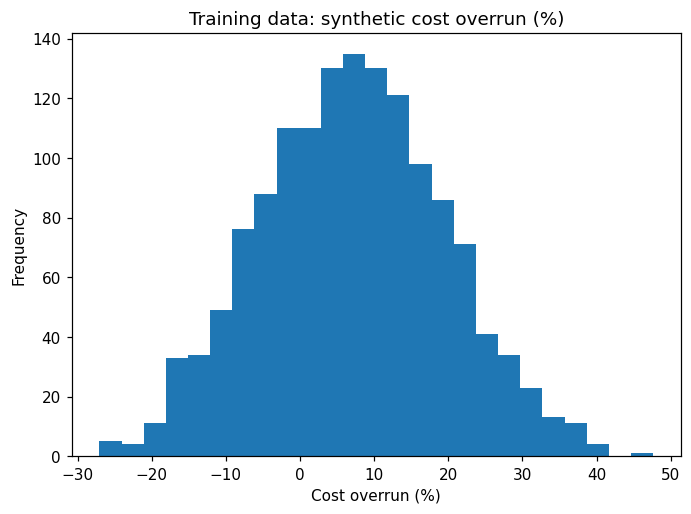

In [5]:
analysis = train_df.assign(overrun_percent=(train_df[TARGET] / train_df["planned_cost_usd"] - 1) * 100)
summary = analysis.groupby("complexity").agg(packages=(TARGET,"size"),
    mean_cost_usd=(TARGET,"mean"), mean_overrun_percent=("overrun_percent","mean"))
print(summary.round(2).to_string())
print("Largest synthetic costs:")
print(analysis.sort_values(TARGET, ascending=False).head(5)[[GROUP,TARGET]].to_string(index=False))
analysis["overrun_percent"].plot.hist(bins=25, title="Training data: synthetic cost overrun (%)")
plt.xlabel("Cost overrun (%)")
plt.tight_layout()

## 7. Training-only preprocessing and model / Подготовка и обучение
Fit the median imputer exclusively on training records inside a Pipeline. Fixed model settings; no test-set tuning.

In [6]:
model = Pipeline([("imputer", SimpleImputer(strategy="median")),
                  ("forest", RandomForestRegressor(n_estimators=160, min_samples_leaf=8, random_state=23, n_jobs=1))])
baseline = DummyRegressor(strategy="mean")
model.fit(X_train, y_train)
baseline.fit(X_train, y_train)
print("Training complete; fitted features:", FEATURES)

Training complete; fitted features: ['planned_cost_usd', 'quantity_m3', 'complexity', 'market_index', 'remote_site']


## 8. Held-out evaluation / Проверка на отложенных данных
Compare with a simple baseline. Synthetic test performance does not establish real-site accuracy.

         model   MAE_USD
 Random forest  23077.72
 Training mean 158465.43
Planned budget  32376.42
Random forest R2: 0.961


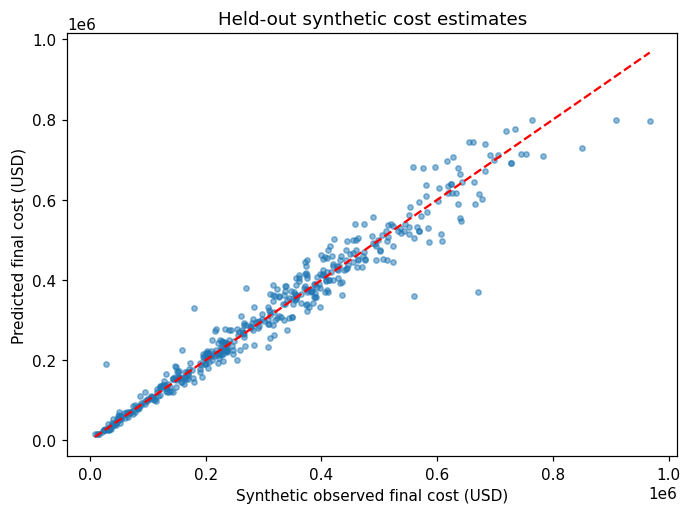

In [7]:
prediction = model.predict(X_test)
baseline_prediction = baseline.predict(X_test)
budget_prediction = X_test["planned_cost_usd"].fillna(X_train["planned_cost_usd"].median())
comparison = pd.DataFrame({"model":["Random forest","Training mean","Planned budget"],
    "MAE_USD":[mean_absolute_error(y_test,prediction),
               mean_absolute_error(y_test,baseline_prediction),
               mean_absolute_error(y_test,budget_prediction)]})
print(comparison.round(2).to_string(index=False))
print("Random forest R2:", round(r2_score(y_test,prediction),4))
assert np.isfinite(prediction).all()
plt.scatter(y_test,prediction,s=12,alpha=.5)
limits=[float(y_test.min()),float(y_test.max())]
plt.plot(limits,limits,"r--")
plt.xlabel("Synthetic observed final cost (USD)")
plt.ylabel("Predicted final cost (USD)")
plt.title("Held-out synthetic cost estimates")
plt.tight_layout()

## 9. Model interpretation / Интерпретация
Permutation importance measures score deterioration after shuffling an input. It is not evidence of causality; correlated features can share importance.

         feature  importance       std
planned_cost_usd 181169.2141 4545.5322
    market_index   7343.4425  275.7617
     quantity_m3   4093.7286 1020.0606
      complexity   2466.4312  380.9837
     remote_site    763.5416  224.0142


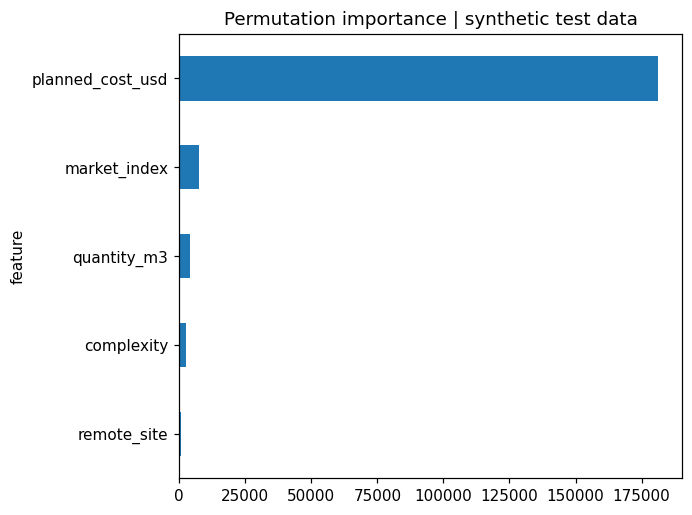

In [8]:
importance = permutation_importance(model, X_test, y_test,
    scoring='neg_mean_absolute_error', n_repeats=5, random_state=29)
importance_df = pd.DataFrame({"feature": FEATURES,
    "importance": importance.importances_mean,
    "std": importance.importances_std}).sort_values("importance", ascending=False)
print(importance_df.round(4).to_string(index=False))
importance_df.sort_values("importance").plot.barh(x="feature", y="importance", legend=False)
plt.title("Permutation importance | synthetic test data")
plt.tight_layout()

## 10. Conclusions and next steps / Выводы
- The workflow demonstrates Pandas preparation, scikit-learn preprocessing, training and baseline comparison.
- All findings depend on the explicitly imposed synthetic mechanism; no measured business savings are claimed.
- This single group holdout is not forward-time validation. A real pilot needs approved historical records, availability checks, temporal evaluation, calibration review and monitoring.
- Engineers and planners own operational decisions. The model cannot operate or stop equipment.

Практика: объясните целевую переменную, зачем отделять проверочные данные и чем модель лучше базового варианта. Затем измените один параметр и сравните результаты, не выбирая лучший вариант по тестовой выборке.
